In [1]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 10.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics]


In [2]:
from ultralytics import YOLO
from google.colab import userdata
import shutil
from pathlib import Path
from ultralytics.data.dataset import DATASET_CACHE_VERSION, YOLODataset
from ultralytics.data.utils import get_hash, load_dataset_cache_file, save_dataset_cache_file
from ultralytics.models.yolo.detect import DetectionTrainer, DetectionValidator
from ultralytics.utils import TQDM, colorstr
import matplotlib.pyplot as plt
import glob
import os
from PIL import Image
import json
import yaml
from google.colab import drive
from collections import defaultdict
import numpy as np

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


In [3]:
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
!unzip -q /content/drive/MyDrive/zerowaste-f-final.zip -d /content/ZeroWaste

In [5]:
training_count = len(os.listdir("/content/ZeroWaste/splits_final_deblurred/train/data"))
test_count = len(os.listdir("/content/ZeroWaste/splits_final_deblurred/test/data"))
validation_count = len(os.listdir("/content/ZeroWaste/splits_final_deblurred/val/data"))

print(f'Training Count: {training_count}')
print(f'Test Count: {test_count}')
print(f'Validation Count: {validation_count}')

Training Count: 3002
Test Count: 929
Validation Count: 572


In [6]:
class COCODataset(YOLODataset):
    """Dataset that reads COCO JSON annotations directly without conversion to .txt files."""

    def __init__(self, *args, json_file="", **kwargs):
        """Initialize the dataset with a COCO JSON annotation file."""
        self.json_file = json_file
        super().__init__(*args, data={"channels": 3}, **kwargs)

    def get_img_files(self, img_path):
        """Image paths are resolved from the JSON file, not from scanning a directory."""
        self.fraction = 1.0  # fraction is applied while scanning a directory, which this dataset skips
        return []

    def cache_labels(self, path=Path("./labels.cache")):
        """Parse COCO JSON and convert annotations to YOLO format. Results are saved to a .cache file."""
        x = {"labels": []}
        with open(self.json_file) as f:
            coco = json.load(f)

        categories = {cat["id"]: i for i, cat in enumerate(sorted(coco["categories"], key=lambda c: c["id"]))}

        img_to_anns = defaultdict(list)
        for ann in coco["annotations"]:
            img_to_anns[ann["image_id"]].append(ann)

        for img_info in TQDM(coco["images"], desc="reading annotations"):
            h, w = img_info["height"], img_info["width"]
            im_file = Path(self.img_path) / img_info["file_name"]
            if not im_file.exists():
                continue

            self.im_files.append(str(im_file))
            bboxes = []
            for ann in img_to_anns.get(img_info["id"], []):
                if ann.get("iscrowd", False):
                    continue
                box = np.array(ann["bbox"], dtype=np.float32)
                box[:2] += box[2:] / 2
                box[[0, 2]] /= w
                box[[1, 3]] /= h
                if box[2] <= 0 or box[3] <= 0:
                    continue
                cls = categories[ann["category_id"]]
                bboxes.append([cls, *box.tolist()])

            lb = np.array(bboxes, dtype=np.float32) if bboxes else np.zeros((0, 5), dtype=np.float32)
            x["labels"].append(
                {
                    "im_file": str(im_file),
                    "shape": (h, w),
                    "cls": lb[:, 0:1],
                    "bboxes": lb[:, 1:],
                    "segments": [],
                    "normalized": True,
                    "bbox_format": "xywh",
                }
            )
        if not x["labels"]:
            raise RuntimeError(f"No images listed in {self.json_file} were found in {self.img_path}")
        x["hash"] = get_hash([self.json_file, str(self.img_path)])
        save_dataset_cache_file(self.prefix, path, x, DATASET_CACHE_VERSION)
        return x

    def get_labels(self):
        """Load labels from .cache file if available, otherwise parse JSON and create the cache."""
        cache_path = Path(self.json_file).with_suffix(".cache")
        try:
            cache = load_dataset_cache_file(cache_path)
            assert cache["version"] == DATASET_CACHE_VERSION
            assert cache["hash"] == get_hash([self.json_file, str(self.img_path)])
            self.im_files = [lb["im_file"] for lb in cache["labels"]]
        except Exception:  # missing, stale, or unreadable cache
            cache = self.cache_labels(cache_path)
        cache.pop("hash", None)
        cache.pop("version", None)
        return cache["labels"]

In [7]:
class COCOTrainer(DetectionTrainer):
    """Trainer that uses COCODataset for direct COCO JSON training."""

    def build_dataset(self, img_path, mode="train", batch=None):
        """Build a COCODataset for the given split using the JSON file from the data config."""
        json_file = self.data["train_json"] if mode == "train" else self.data["val_json"]
        return COCODataset(
            img_path=img_path,
            json_file=json_file,
            imgsz=self.args.imgsz,
            batch_size=batch,
            augment=mode == "train",
            hyp=self.args,
            rect=self.args.rect or mode == "val",
            cache=self.args.cache or None,
            single_cls=self.args.single_cls or False,
            stride=int(self.model.stride.max()) if hasattr(self, "model") and self.model else 32,
            pad=0.0 if mode == "train" else 0.5,
            prefix=colorstr(f"{mode}: "),
            task=self.args.task,
            classes=self.args.classes,
            fraction=self.args.fraction if mode == "train" else 1.0,
        )

In [13]:
class COCOValidator(DetectionValidator):

    def build_dataset(self, img_path, mode="val", batch=None):

        return COCODataset(
            img_path=img_path,
            json_file=self.data["test_json"],
            imgsz=self.args.imgsz,
            batch_size=batch,
            augment=False,
            hyp=self.args,
            rect=self.args.rect or mode == "val",
            cache=self.args.cache or None,
            single_cls=self.args.single_cls or False,
            stride=self.stride,
            pad=0.5,
            prefix=colorstr("val: "),
            task=self.args.task,
            classes=self.args.classes,
            fraction=1.0,
        )

In [12]:

import json
import yaml
from pathlib import Path

# Dataset root directory
ROOT = Path("/content/ZeroWaste/splits_final_deblurred")

# COCO annotation files
TRAIN_JSON = ROOT / "train/labels.json"
VAL_JSON = ROOT / "val/labels.json"
TEST_JSON = ROOT / "test/labels.json"

# Image directories
TRAIN_IMAGES = ROOT / "train/data"
VAL_IMAGES = ROOT / "val/data"
TEST_IMAGES = ROOT / "test/data"


def get_class_names(json_path):
    with open(json_path, "r") as f:
        coco = json.load(f)

    categories = sorted(coco["categories"], key=lambda x: x["id"])

    return {
        i: category["name"]
        for i, category in enumerate(categories)
    }


# Read class names from training annotations
names = get_class_names(TRAIN_JSON)

# Verify categories match across all splits
for split, json_path in [
    ("validation", VAL_JSON),
    ("test", TEST_JSON)
]:
    split_names = get_class_names(json_path)

    if names != split_names:
        raise ValueError(
            f"{split.capitalize()} categories do not match training categories!"
        )

# Create dataset configuration
config = {
    "path": str(ROOT),
    "train": str(TRAIN_IMAGES),
    "val": str(VAL_IMAGES),
    "test": str(TEST_IMAGES),
    "train_json": str(TRAIN_JSON),
    "val_json": str(VAL_JSON),
    "test_json": str(TEST_JSON),
    "names": names,
}

# Save YAML
yaml_path = ROOT / "dataset.yaml"

with open(yaml_path, "w") as f:
    yaml.safe_dump(config, f, sort_keys=False)

print(f"Dataset YAML created: {yaml_path}")
print("\nGenerated configuration:")
print(yaml_path.read_text())


Dataset YAML created: /content/ZeroWaste/splits_final_deblurred/dataset.yaml

Generated configuration:
path: /content/ZeroWaste/splits_final_deblurred
train: /content/ZeroWaste/splits_final_deblurred/train/data
val: /content/ZeroWaste/splits_final_deblurred/val/data
test: /content/ZeroWaste/splits_final_deblurred/test/data
train_json: /content/ZeroWaste/splits_final_deblurred/train/labels.json
val_json: /content/ZeroWaste/splits_final_deblurred/val/labels.json
test_json: /content/ZeroWaste/splits_final_deblurred/test/labels.json
names:
  0: rigid_plastic
  1: cardboard
  2: metal
  3: soft_plastic



Training Model

In [10]:
model = YOLO("yolo26n.pt")

results = model.train(
    data="/content/ZeroWaste/splits_final_deblurred/dataset.yaml",
    epochs=100,
    imgsz=640,
    batch=16,
    name="zerowaste_yolo26",
    save=True,
    trainer = COCOTrainer
)

print("Training completed!")
print("Results directory:", results.save_dir)

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/ZeroWaste/splits_final_deblurred/dataset.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=zerowaste_yolo26, nbs=64, nms=No

Evaluating Model

In [14]:
best_model = YOLO("/content/runs/detect/zerowaste_yolo26/weights/best.pt")

test_metrics = best_model.val(
    data="/content/ZeroWaste/splits_final_deblurred/dataset.yaml",
    validator=COCOValidator,
    imgsz=640,
    batch=16,
    split="test"
)

print("Test mAP50-95:", test_metrics.box.map)
print("Test mAP50:", test_metrics.box.map50)
print("Test mAP75:", test_metrics.box.map75)
print("Test Precision:", test_metrics.box.mp)
print("Test Recall:", test_metrics.box.mr)

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
YOLO26n summary (fused): 121 layers, 2,390,464 parameters, 0 gradients, 5.4 GFLOPs
reading annotations: 100% ━━━━━━━━━━━━ 929/929 11.2Kit/s 0.1s
val: New cache created: /content/ZeroWaste/splits_final_deblurred/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 59/59 5.4it/s 10.9s
                   all        929       5077      0.393      0.398      0.345       0.24
         rigid_plastic        240        315      0.386      0.313       0.28      0.208
             cardboard        829       3449      0.491      0.565      0.493      0.345
                 metal         57         63      0.244      0.222      0.153      0.109
          soft_plastic        649       1250      0.451      0.494      0.455      0.296
Speed: 0.5ms preprocess, 1.1ms inference, 0.0ms loss, 1.1ms postprocess per image
Results saved to /content/runs/

Predictions

In [15]:
results = best_model.predict(
    source="/content/ZeroWaste/splits_final_deblurred/test/data",
    imgsz=640,
    conf=0.25,
    save=True,
    max_det=100
)


image 1/929 /content/ZeroWaste/splits_final_deblurred/test/data/01_frame_000680.PNG: 384x640 6 cardboards, 3 soft_plastics, 10.8ms
image 2/929 /content/ZeroWaste/splits_final_deblurred/test/data/01_frame_000690.PNG: 384x640 1 rigid_plastic, 4 cardboards, 4 soft_plastics, 12.0ms
image 3/929 /content/ZeroWaste/splits_final_deblurred/test/data/01_frame_000700.PNG: 384x640 1 rigid_plastic, 6 cardboards, 1 soft_plastic, 11.3ms
image 4/929 /content/ZeroWaste/splits_final_deblurred/test/data/01_frame_000710.PNG: 384x640 1 rigid_plastic, 5 cardboards, 3 soft_plastics, 11.4ms
image 5/929 /content/ZeroWaste/splits_final_deblurred/test/data/01_frame_000720.PNG: 384x640 4 cardboards, 2 soft_plastics, 12.0ms
image 6/929 /content/ZeroWaste/splits_final_deblurred/test/data/01_frame_000730.PNG: 384x640 4 cardboards, 1 soft_plastic, 11.5ms
image 7/929 /content/ZeroWaste/splits_final_deblurred/test/data/01_frame_000740.PNG: 384x640 1 rigid_plastic, 5 cardboards, 1 soft_plastic, 11.6ms
image 8/929 /cont

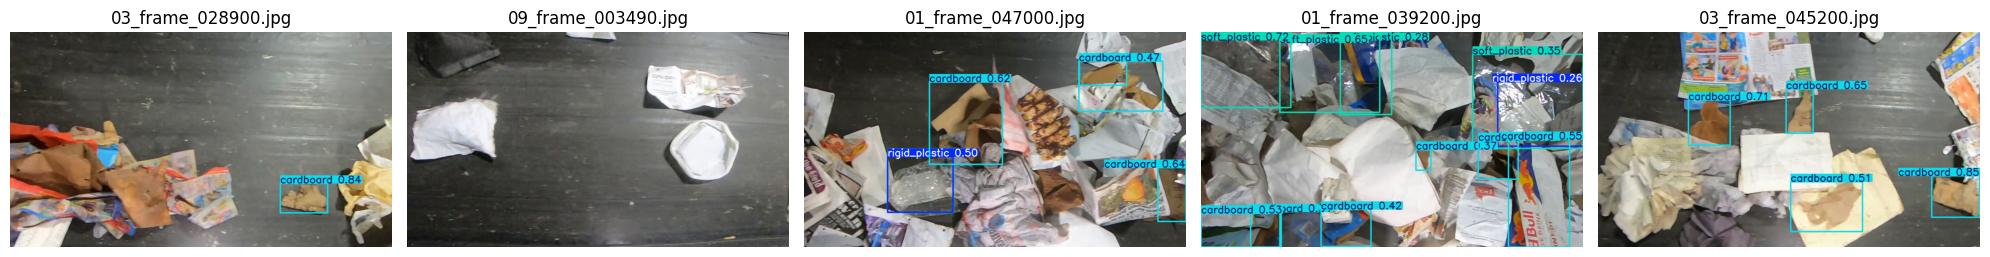

In [16]:
# Locate saved prediction images
prediction_dir = results[0].save_dir
image_paths = glob.glob(
    os.path.join(str(prediction_dir), "*")
)

image_paths = [
    p for p in image_paths
    if p.lower().endswith((".jpg", ".jpeg", ".png"))
][:5]

# Display five images
fig, axes = plt.subplots(1, 5, figsize=(20, 6))

for ax, image_path in zip(axes, image_paths):
    img = Image.open(image_path)
    ax.imshow(img)
    ax.set_title(os.path.basename(image_path))
    ax.axis("off")

plt.tight_layout()
plt.show()

In [17]:
from google.colab import files
files.download("/content/runs/detect/zerowaste_yolo26/weights/best.pt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>